# Linear Regression Diagnostics: Residuals, Homoscedasticity, TSS, RSS, and \(R^2\)

This notebook uses the **real diabetes dataset** built into scikit-learn.

The story is:

$$
\text{residuals}
\rightarrow
\text{homoscedasticity / heteroscedasticity}
\rightarrow
TSS,\ RSS
\rightarrow
R^2.
$$

At the end, we use controlled examples to show how \(R^2\) changes from values near \(0\) to \(1\).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

data = load_diabetes(as_frame=True)
df = data.frame.copy()

print("Shape:", df.shape)
print("Predictors:", data.feature_names)
df.head()

Shape: (442, 11)
Predictors: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 1. Real data: predicting diabetes progression from BMI

We begin with a simple regression

$$
Y_i=\beta_0+\beta_1X_i+\varepsilon_i,
$$

where \(X_i\) is BMI and \(Y_i\) is disease progression.

In [3]:
X = df[["bmi"]].to_numpy()
y = df["target"].to_numpy()

model = LinearRegression().fit(X, y)
y_hat = model.predict(X)
residuals = y - y_hat

print(f"Intercept = {model.intercept_:.3f}")
print(f"Slope     = {model.coef_[0]:.3f}")

Intercept = 152.133
Slope     = 949.435


## 2. Residuals

For observation \(i\),

$$
\hat y_i=\hat\beta_0+\hat\beta_1x_i
$$

is the fitted value, and

$$
\boxed{e_i=y_i-\hat y_i}
$$

is the residual.

It is the vertical distance between the observed point and the fitted line.

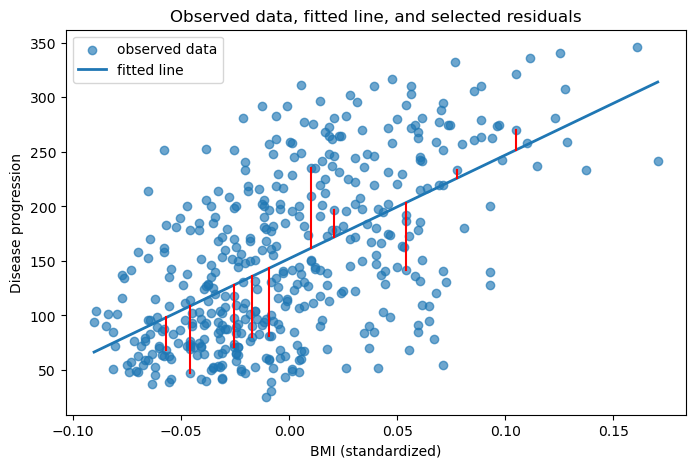

In [7]:
order = np.argsort(X[:,0])

plt.figure(figsize=(8,5))
plt.scatter(X[:,0], y, alpha=0.65, label="observed data")
plt.plot(X[order,0], y_hat[order], linewidth=2, label="fitted line")

idx = np.linspace(20, len(y)-20, 10, dtype=int)
for i in idx:
    plt.plot([X[i,0], X[i,0]], [y_hat[i], y[i]], linewidth=1.5,color='red')

plt.xlabel("BMI (standardized)")
plt.ylabel("Disease progression")
plt.title("Observed data, fitted line, and selected residuals")
plt.legend()
plt.savefig('resi-lines.png',dpi=500)

## 3. Residual plot

A standard diagnostic is to plot residuals against fitted values,

$$
\hat y_i \quad \text{vs.} \quad e_i.
$$

If the linear model is reasonable, we hope to see residuals scattered around zero without a strong systematic pattern.

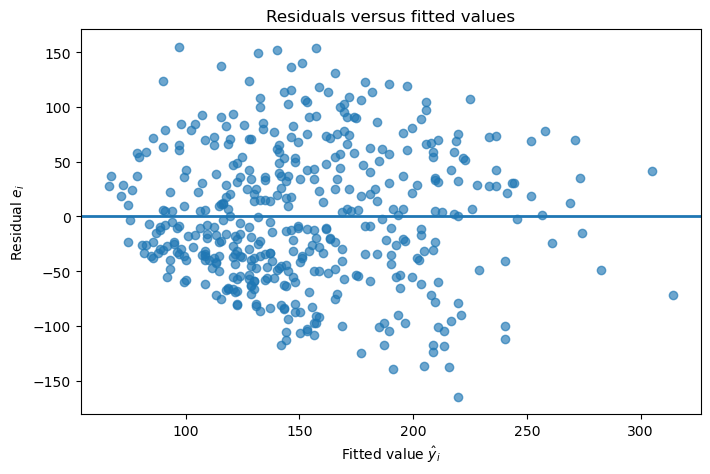

In [6]:
plt.figure(figsize=(8,5))
plt.scatter(y_hat, residuals, alpha=0.65)
plt.axhline(0, linewidth=2)
plt.xlabel(r"Fitted value $\hat y_i$")
plt.ylabel(r"Residual $e_i$")
plt.title("Residuals versus fitted values")
plt.savefig('resi.png',dpi=500)

## 4. Homoscedasticity and heteroscedasticity

Homoscedasticity means

$$
\boxed{\operatorname{Var}(\varepsilon_i\mid X_i)=\sigma^2,}
$$

so the residual spread is approximately constant.

Heteroscedasticity means

$$
\boxed{\operatorname{Var}(\varepsilon_i\mid X_i)=\sigma^2(X_i),}
$$

so the residual spread changes systematically with the predictors.

This concerns the **variance of the residuals**, not the scale or variance of the predictors.

### Controlled illustration

The next example is synthetic only to make the difference visually obvious. Both datasets have the same conditional mean,

$$
E[Y\mid X=x]=1+2x,
$$

but different error variances.

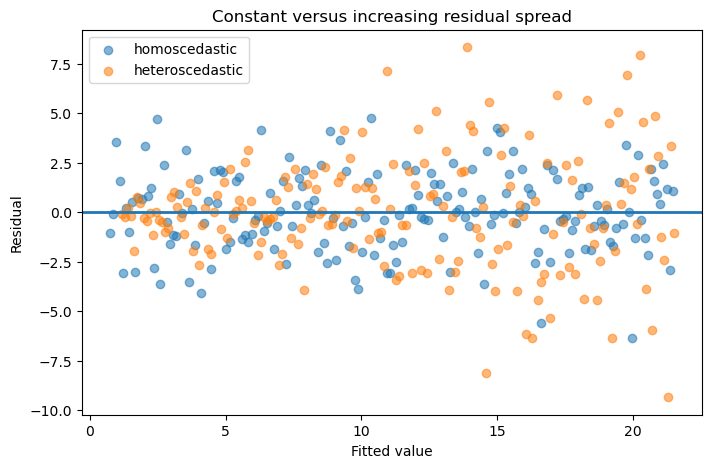

In [18]:
rng = np.random.default_rng(4)
x_demo = np.linspace(0,10,180)
mu = 1 + 2*x_demo

y_homo = mu + rng.normal(0, 2.0, len(x_demo))
sigma_x = 0.5 + 0.45*x_demo
y_hetero = mu + rng.normal(0, sigma_x, len(x_demo))

m1 = LinearRegression().fit(x_demo.reshape(-1,1), y_homo)
m2 = LinearRegression().fit(x_demo.reshape(-1,1), y_hetero)

fit1 = m1.predict(x_demo.reshape(-1,1))
fit2 = m2.predict(x_demo.reshape(-1,1))

res1 = y_homo - fit1
res2 = y_hetero - fit2

plt.figure(figsize=(8,5))
plt.scatter(fit1, res1, alpha=0.55, label="homoscedastic")
plt.scatter(fit2, res2, alpha=0.55, label="heteroscedastic")
plt.axhline(0, linewidth=2)
plt.xlabel("Fitted value")
plt.ylabel("Residual")
plt.title("Constant versus increasing residual spread")
plt.legend()
plt.show()

In the heteroscedastic case the residual plot develops a fan shape: the spread grows with the fitted value.

## 5. TSS: the mean-only baseline

Before using any predictor, the simplest prediction is

$$
\hat y_i=\bar y.
$$

Its squared error is

$$
\boxed{TSS=\sum_{i=1}^n (y_i-\bar y)^2.}
$$

Thus, \(TSS\) measures the total variation in \(Y\) around its mean.

In [19]:
y_bar = y.mean()
TSS = np.sum((y-y_bar)**2)

print(f"Mean response = {y_bar:.3f}")
print(f"TSS = {TSS:.3f}")

Mean response = 152.133
TSS = 2621009.124


## 6. RSS: the error left after regression

After fitting the regression model, the residual sum of squares is

$$
\boxed{RSS=\sum_{i=1}^n (y_i-\hat y_i)^2.}
$$

This is the part of the variation in \(Y\) that remains unexplained by the regression.

In [20]:
RSS = np.sum((y-y_hat)**2)

print(f"RSS = {RSS:.3f}")
print(f"TSS - RSS = {TSS-RSS:.3f}")

RSS = 1719581.811
TSS - RSS = 901427.314


For OLS with an intercept,

$$
TSS
=
\underbrace{\sum_i(\hat y_i-\bar y)^2}_{\text{explained variation}}
+
\underbrace{\sum_i(y_i-\hat y_i)^2}_{RSS}.
$$

In [22]:
ESS = np.sum((y_hat-y_bar)**2)

print(f"Explained SS = {ESS:.3f}")
print(f"RSS          = {RSS:.3f}")
print(f"ESS + RSS    = {ESS+RSS:.3f}")
print(f"TSS          = {TSS:.3f}")

Explained SS = 901427.314
RSS          = 1719581.811
ESS + RSS    = 2621009.124
TSS          = 2621009.124


## 7. The coefficient of determination \(R^2\)

$$
\boxed{
R^2
=
\frac{TSS-RSS}{TSS}
=
1-\frac{RSS}{TSS}.
}
$$

Interpretation:

$$
\boxed{
R^2
=
\text{fraction of the variability in \(Y\) accounted for by the regression model}.
}
$$

- \(R^2=0\): no improvement over predicting \(\bar y\) for everyone.
- \(R^2=1\): perfect prediction.

In [23]:
R2_manual = 1 - RSS/TSS
R2_sklearn = r2_score(y, y_hat)

print(f"Manual R^2  = {R2_manual:.4f}")
print(f"sklearn R^2 = {R2_sklearn:.4f}")

Manual R^2  = 0.3439
sklearn R^2 = 0.3439


## 8. Real-data comparison: \(R^2\) as predictors are added

Using the same diabetes dataset, compare:

1. mean-only prediction,
2. BMI only,
3. BMI + blood pressure,
4. all ten predictors.

This shows how useful predictors reduce RSS and increase training \(R^2\).

In [24]:
feature_sets = {
    "Mean only": [],
    "BMI": ["bmi"],
    "BMI + BP": ["bmi","bp"],
    "All 10 predictors": list(data.feature_names),
}

rows = []

for name, features in feature_sets.items():
    if not features:
        pred = np.full(len(y), y.mean())
    else:
        Xf = df[features].to_numpy()
        m = LinearRegression().fit(Xf, y)
        pred = m.predict(Xf)

    rss = np.sum((y-pred)**2)
    r2 = 1-rss/TSS

    rows.append([name, len(features), rss, r2])

comparison = pd.DataFrame(rows, columns=["Model","Number of predictors","RSS","R^2"])
comparison

,Model,Number of predictors,RSS,R^2
0,Mean only,0,2.621009e+06,0.000000
1,BMI,1,1.719582e+06,0.343924
2,BMI + BP,2,1.583105e+06,0.395994
3,All 10 predictors,10,1.263986e+06,0.517748


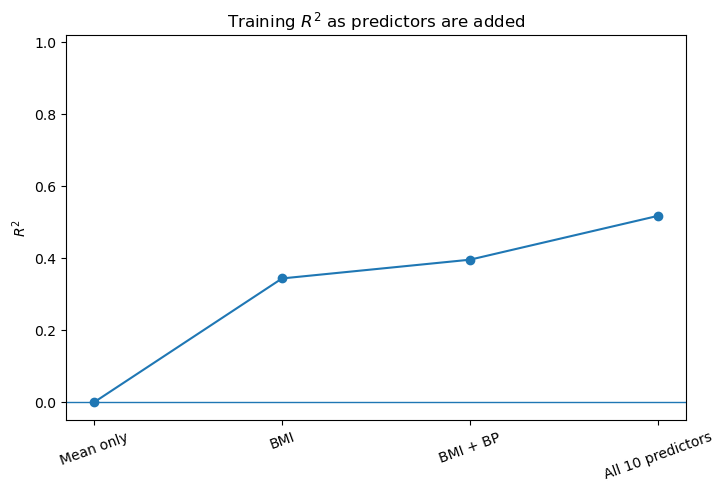

In [25]:
plt.figure(figsize=(8,5))
plt.plot(comparison["Model"], comparison["R^2"], marker="o")
plt.axhline(0, linewidth=1)
plt.ylim(-0.05,1.02)
plt.ylabel(r"$R^2$")
plt.title(r"Training $R^2$ as predictors are added")
plt.xticks(rotation=20)
plt.show()

The mean-only model has

$$
R^2=0
$$

by construction.

Adding useful predictors lowers the training RSS and therefore increases training \(R^2\).

However, training \(R^2\) can never decrease when more predictors are added, so \(R^2\) alone does not tell us whether the richer model generalizes better.

## 9. Seeing \(R^2\) change from \(0\) to \(1\)

The following controlled examples are synthetic. Their only purpose is to make the meaning of \(R^2\) visually transparent.

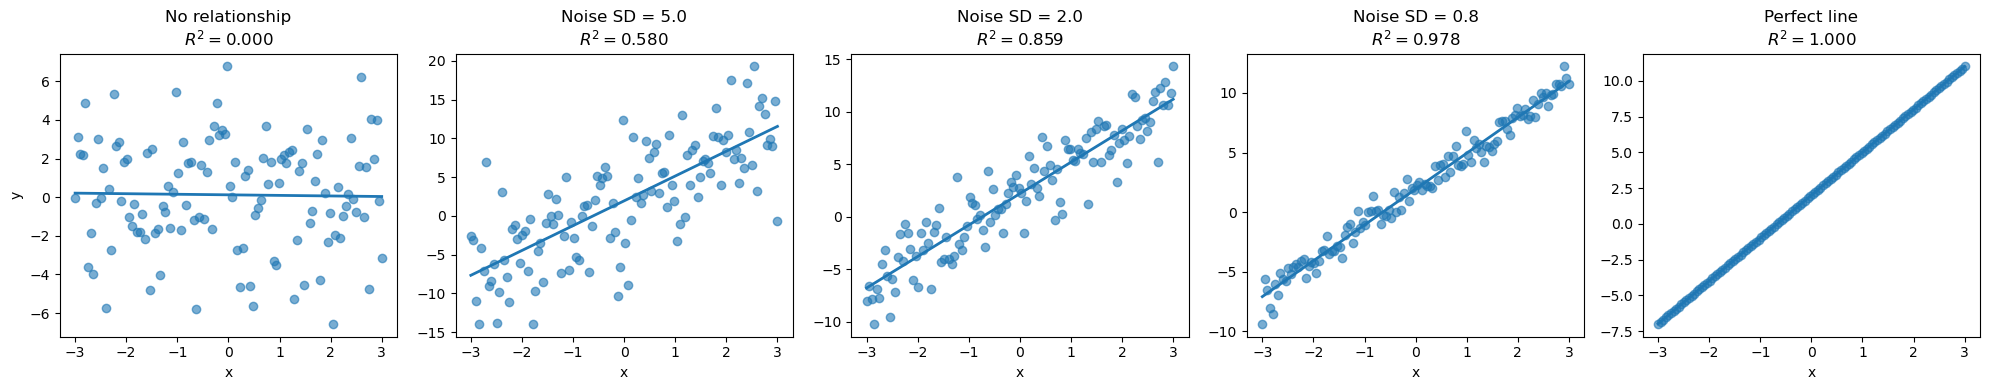

In [26]:
rng = np.random.default_rng(12)
x = np.linspace(-3,3,120)

datasets = []

# R^2 near 0: y independent of x
y0 = rng.normal(0,3,len(x))
datasets.append(("No relationship", y0))

# increasingly stronger linear signal
for noise_sd in [5.0, 2.0, 0.8]:
    yy = 2 + 3*x + rng.normal(0,noise_sd,len(x))
    datasets.append((f"Noise SD = {noise_sd}", yy))

# R^2 = 1
y1 = 2 + 3*x
datasets.append(("Perfect line", y1))

fig, axes = plt.subplots(1,5,figsize=(20,4))

for ax, (label, yy) in zip(axes, datasets):
    m = LinearRegression().fit(x.reshape(-1,1), yy)
    pred = m.predict(x.reshape(-1,1))
    r2 = r2_score(yy,pred)

    ax.scatter(x,yy,alpha=0.6)
    ax.plot(x,pred,linewidth=2)
    ax.set_title(f"{label}\n$R^2={r2:.3f}$")
    ax.set_xlabel("x")

axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

As the relationship becomes tighter, RSS becomes smaller relative to TSS, so \(R^2\) increases.

When \(X\) carries essentially no predictive information,

\[
R^2\approx 0.
\]

For a perfect linear relationship,

\[
RSS=0,
\]

and therefore

\[
\boxed{R^2=1.}
\]

## 10. Summary

\[
\boxed{e_i=y_i-\hat y_i}
\]

is the residual.

Homoscedasticity means constant conditional residual variance,

\[
\boxed{\operatorname{Var}(\varepsilon\mid X)=\sigma^2,}
\]

while heteroscedasticity means this variance changes with the predictors.

The mean-only model has error

\[
\boxed{TSS=\sum_i(y_i-\bar y)^2,}
\]

while the regression model has error

\[
\boxed{RSS=\sum_i(y_i-\hat y_i)^2.}
\]

Finally,

\[
\boxed{R^2=1-\frac{RSS}{TSS}}
\]

measures the relative reduction in squared error obtained by using the regression model instead of predicting the sample mean for every observation.